# Step 7 — Proyek Mini: Membangun Mesin Pencari Utuh

**Tujuan praktikum**
1. Mahasiswa mampu mengintegrasikan preprocessing, indexing, model retrieval, dan evaluasi menjadi satu sistem.
2. Mahasiswa mampu melakukan eksperimen ablasi untuk melihat kontribusi tiap tahap preprocessing.
3. Mahasiswa mampu menyajikan hasil pencarian yang informatif (judul, skor, cuplikan).

## Langkah 1 — Menyiapkan data Modul 7

Di bagian ini saya memakai tiga CSV kelompok: `korpus.csv`, `queries.csv`, dan `qrels.csv`. Data Modul 1–6 milik dosen tidak diubah. Supaya tidak tertukar dengan variabel notebook lain, DataFrame dokumen disimpan dengan nama `df_korpus`.

In [30]:
# Jika Sastrawi belum terpasang, jalankan perintah berikut sekali:
# %pip install Sastrawi

from pathlib import Path
from collections import Counter, defaultdict
from functools import lru_cache
from IPython.display import display
import math
import re
import warnings

import pandas as pd
import matplotlib.pyplot as plt

pd.set_option('display.max_colwidth', 100)

try:
    from Sastrawi.Stemmer.StemmerFactory import StemmerFactory
    from Sastrawi.StopWordRemover.StopWordRemoverFactory import StopWordRemoverFactory
    stemmer = StemmerFactory().create_stemmer()
    STOPWORDS = set(StopWordRemoverFactory().get_stop_words())
    SASTRAWI_AKTIF = True
except ImportError:
    stemmer = None
    STOPWORDS = set('dan yang di ke dari dengan untuk pada dalam adalah sebagai serta ini itu oleh atau dapat agar akan juga sebuah suatu telah karena kepada antara melalui tanpa menjadi tidak lebih tentang pada'.split())
    SASTRAWI_AKTIF = False
    warnings.warn('Sastrawi belum terinstal; stemming dilewati. Nilai evaluasi dapat berubah setelah Sastrawi dipasang.')

print('Sastrawi aktif:', SASTRAWI_AKTIF)

Sastrawi aktif: True


In [34]:
# Cari tiga file dalam folder Data yang sama, bukan mengambil CSV secara acak.
folder_kandidat = [Path.cwd() / 'Data', Path.cwd().parent / 'Data',
                   Path.cwd(), Path.cwd().parent]
folder_data = next((p for p in folder_kandidat if
                    all((p / n).is_file() for n in ('korpus.csv', 'queries.csv', 'qrels.csv'))), None)
if folder_data is None:
    raise FileNotFoundError('Folder Data harus berisi korpus.csv, queries.csv, dan qrels.csv')

df_korpus = pd.read_csv(folder_data / 'korpus.csv', encoding='utf-8-sig')
df_queries = pd.read_csv(folder_data / 'queries.csv', encoding='utf-8-sig')
df_qrels = pd.read_csv(folder_data / 'qrels.csv', encoding='utf-8-sig')
for data in (df_korpus, df_queries, df_qrels):
    data.columns = data.columns.str.strip()

# Kolom sesuai dengan file korpus kelompok; error id_doc sebelumnya dicegah di sini.
assert {'doc_id', 'judul', 'isi'} <= set(df_korpus.columns), f'Kolom korpus: {df_korpus.columns.tolist()}'
assert {'query_id', 'query'} <= set(df_queries.columns), f'Kolom query: {df_queries.columns.tolist()}'
assert {'query_id', 'doc_id', 'relevance'} <= set(df_qrels.columns)
assert not df_korpus['doc_id'].duplicated().any(), 'Ada id_doc duplikat'
assert not df_queries['query_id'].duplicated().any(), 'Ada query_id duplikat'
assert not df_qrels.duplicated(['query_id', 'doc_id']).any(), 'Ada qrels duplikat'
assert df_qrels['doc_id'].isin(df_korpus['doc_id']).all(), 'ID qrels tidak ditemukan di korpus'
assert df_qrels['query_id'].isin(df_queries['query_id']).all(), 'ID qrels tidak ditemukan di queries'
assert df_qrels['relevance'].isin([0, 1, 2, 3]).all(), 'Ada skor qrels di luar 0-3'
if len(df_korpus) == 30 and len(df_queries) == 8:
    raise ValueError('Terdeteksi dataset dosen (30 dokumen, 8 query). Untuk Modul 7, gunakan folder Data dalam paket ini yang berisi dataset kelompok.')
assert not df_korpus[['doc_id', 'judul', 'isi']].isna().any().any(), 'Ada konten dokumen kosong'

DAFTAR_QUERY = dict(zip(df_queries['query_id'], df_queries['query']))
print('Folder data:', folder_data.resolve())
print('Jumlah dokumen:', len(df_korpus))
print('Jumlah query:', len(df_queries))
print('Jumlah qrels tercatat:', len(df_qrels))
display(df_korpus[['doc_id', 'judul']].head())

Folder data: C:\Users\ASUS\Downloads\Project STKI\Data
Jumlah dokumen: 50
Jumlah query: 25
Jumlah qrels tercatat: 59


,doc_id,judul
0,D01,Pertanian
1,D02,Peran AI Generatif dalam Industri Kreatif
2,D03,Peta
3,D04,Branding Agency
4,D05,Machine Learning


## Langkah 2 — Preprocessing dan pembuatan indeks

Teks diubah menjadi huruf kecil, dipisahkan menjadi token, lalu stopword dan imbuhan bisa dihilangkan. Kode memakai BM25 sebagai model utama dan TF-IDF sebagai pembanding dalam eksperimen ablasi.

In [35]:
def tokenize(teks):
    return re.findall(r'[a-z0-9]+', str(teks).lower())

@lru_cache(maxsize=120000)
def stem_kata(kata):
    return stemmer.stem(kata) if stemmer is not None else kata

def preprocess(teks, use_stopword=True, use_stemming=True):
    hasil = tokenize(teks)
    if use_stopword:
        hasil = [t for t in hasil if t not in STOPWORDS]
    if use_stemming and SASTRAWI_AKTIF:
        hasil = [stem_kata(t) for t in hasil]
    return hasil

class BM25Model:
    def __init__(self, dokumen, k1=1.5, b=0.75):
        self.k1, self.b = k1, b
        self.n = len(dokumen)
        self.panjang = {d: len(t) for d, t in dokumen.items()}
        self.rata_panjang = sum(self.panjang.values()) / max(self.n, 1)
        self.indeks = defaultdict(dict)
        for d, token in dokumen.items():
            for term, tf in Counter(token).items():
                self.indeks[term][d] = tf
        self.idf = {t: math.log(1 + (self.n - len(p) + 0.5) / (len(p) + 0.5))
                    for t, p in self.indeks.items()}

    def search(self, token_query, k=10):
        skor = defaultdict(float)
        for term in set(token_query):
            for d, tf in self.indeks.get(term, {}).items():
                norm = self.k1 * (1 - self.b + self.b * self.panjang[d] / max(self.rata_panjang, 1e-12))
                skor[d] += self.idf[term] * (tf * (self.k1 + 1)) / (tf + norm)
        return sorted(skor.items(), key=lambda x: (-x[1], x[0]))[:k]

class TfidfModel:
    def __init__(self, dokumen):
        self.n = len(dokumen)
        df = Counter(t for token in dokumen.values() for t in set(token))
        self.idf = {t: math.log10(self.n / n) for t, n in df.items()}
        self.indeks = defaultdict(dict)
        for d, token in dokumen.items():
            bobot = {t: (1 + math.log10(tf)) * self.idf[t]
                     for t, tf in Counter(token).items()}
            panjang = math.sqrt(sum(v * v for v in bobot.values()))
            if panjang:
                for t, v in bobot.items():
                    if v: self.indeks[t][d] = v / panjang

    def search(self, token_query, k=10):
        bobot_q = {(t): (1 + math.log10(tf)) * self.idf[t]
                   for t, tf in Counter(token_query).items() if t in self.idf}
        panjang_q = math.sqrt(sum(v * v for v in bobot_q.values()))
        skor = defaultdict(float)
        if panjang_q:
            for t, v in bobot_q.items():
                for d, bobot_d in self.indeks.get(t, {}).items():
                    skor[d] += (v / panjang_q) * bobot_d
        return sorted(skor.items(), key=lambda x: (-x[1], x[0]))[:k]

## Langkah 3 — Kelas `MesinPencari`

Kelas berikut menjadi satu tempat untuk pencarian, peringkat dokumen, dan cuplikan hasil. Opsi `ekspansi_sinonim` bisa diaktifkan untuk meningkatkan pencarian tanpa mengubah data asli.

In [37]:
# Sinonim sederhana yang relevan dengan istilah dalam korpus kelompok.
SINONIM = {
    'rumah pintar': ['smart home', 'rumah cerdas'],
    'rumah cerdas': ['rumah pintar', 'smart home'],
    'smart home': ['rumah pintar', 'rumah cerdas'],
    'smartphone': ['telepon pintar', 'ponsel'],
    'ponsel': ['smartphone', 'telepon pintar'],
    'kecerdasan buatan': ['ai', 'artificial intelligence'],
    'ai': ['kecerdasan buatan', 'artificial intelligence'],
    'energi matahari': ['energi surya', 'tenaga surya'],
    'energi surya': ['energi matahari', 'tenaga surya'],
    'machine learning': ['pembelajaran mesin'],
    'pembelajaran mesin': ['machine learning'],
    'data besar': ['big data', 'skala besar'],
    'basis data': ['database'],
    'kebakaran hutan': ['karhutla'],
    'malware': ['perangkat lunak berbahaya'],
    'daur ulang': ['mengolah kembali'],
}

def ekspansi_token(query, opsi):
    teks = ' '.join(tokenize(query))
    hasil = preprocess(query, **opsi)
    for pemicu, padanan in SINONIM.items():
        if re.search(r'(?<!\w)' + re.escape(pemicu) + r'(?!\w)', teks):
            for alternatif in padanan:
                hasil.extend(preprocess(alternatif, **opsi))
    return list(dict.fromkeys(hasil))

class MesinPencari:
    def __init__(self, model='bm25', use_stopword=True, use_stemming=True,
                 ekspansi_sinonim=False, k1=1.5, b=0.75):
        if model not in ('bm25', 'tfidf'):
            raise ValueError('model harus bm25 atau tfidf')
        self.nama_model = model
        self.opsi = {'use_stopword': use_stopword, 'use_stemming': use_stemming}
        self.ekspansi_sinonim = ekspansi_sinonim
        # Gunakan df_korpus, bukan variabel umum bernama korpus yang bisa tertimpa cell lain.
        self.korpus = df_korpus.copy().set_index('doc_id', verify_integrity=True)
        token_dok = {
            r.doc_id: preprocess(f'{r.judul}. {r.isi}', **self.opsi)
            for r in df_korpus.itertuples(index=False)
        }
        self.model = (BM25Model(token_dok, k1=k1, b=b)
                      if model == 'bm25' else TfidfModel(token_dok))

    def token_query(self, query):
        if self.ekspansi_sinonim:
            return ekspansi_token(query, self.opsi)
        return preprocess(query, **self.opsi)

    def skor_pencarian(self, query, k=10):
        return self.model.search(self.token_query(query), k=k)

    def cari(self, query, k=10):
        return [d for d, _ in self.skor_pencarian(query, k)]

    def tampilkan(self, query, k=5):
        token_q = set(self.token_query(query))
        baris = []
        for posisi, (doc_id, skor) in enumerate(self.skor_pencarian(query, k), 1):
            row = self.korpus.loc[doc_id]
            kalimat = re.split(r'(?<=[.!?])\s+', str(row['isi']))
            cuplikan = max(kalimat, key=lambda s: len(token_q & set(preprocess(s, **self.opsi))))
            baris.append({'Peringkat': posisi, 'Doc ID': doc_id, 'Judul': row['judul'],
                          'Skor': round(skor, 4), 'Cuplikan': cuplikan[:200]})
        hasil = pd.DataFrame(baris, columns=['Peringkat', 'Doc ID', 'Judul', 'Skor', 'Cuplikan'])
        print(f'Model: {self.nama_model.upper()} | Sinonim: {self.ekspansi_sinonim} | Query: {query}')
        display(hasil)
        return hasil

mesin = MesinPencari(model='bm25')
mesin.tampilkan(DAFTAR_QUERY['Q01'], k=5)
mesin.tampilkan(DAFTAR_QUERY['Q03'], k=5)

C:\Users\ASUS\AppData\Local\Temp\ipykernel_7588\3255029238.py:39: Pandas4Warning: The 'verify_integrity' keyword in DataFrame.set_index is deprecated and will be removed in a future version. Directly check the result.index.is_unique instead.
  self.korpus = df_korpus.copy().set_index('doc_id', verify_integrity=True)


Model: BM25 | Sinonim: False | Query: Teknologi kecerdasan buatan untuk menghasilkan konten kreatif


,Peringkat,Doc ID,Judul,Skor,Cuplikan
0,1,D02,Peran AI Generatif dalam Industri Kreatif,17.0943,Kemajuan teknologi kecerdasan buatan (AI) terus berkembang pesat dan memengaruhi berbagai sektor...
1,2,D23,Generative AI: Teknologi Masa Depan yang Menciptakan Peluang Baru,11.3795,Generative AI (Artificial Intelligence) adalah cabang kecerdasan buatan yang mampu menciptakan k...
2,3,D43,Content Creator,5.8682,Content Creator adalah seseorang atau tim yang membuat dan membagikan konten digital dalam bentu...
3,4,D36,Energi Surya,5.2793,"Energi ini dapat dimanfaatkan dengan menggunakan serangkaian teknologi seperti pemanas surya, fo..."
4,5,D01,Pertanian,4.6660,"""Pertanian mencakup kegiatan budidaya tanaman dan peternakan untuk menghasilkan pangan, bahan ba..."


Model: BM25 | Sinonim: False | Query: Penyebab dan dampak kebakaran hutan dan lahan


,Peringkat,Doc ID,Judul,Skor,Cuplikan
0,1,D15,"Kebakaran Hutan Kalimantan: Penyebab, Dampak, dan Cara Mencegahnya",16.6428,"Kebakaran hutan Kalimantan merupakan ancaman lingkungan yang dapat merusak habitat, menurunkan k..."
1,2,D16,Mengapa Kebakaran Hutan dan Lahan Selalu Terjadi?,14.0313,"Setiap musim kemarau tiba, kekhawatiran yang sama kembali menghampiri: kebakaran hutan dan lahan..."
2,3,D49,Apa Itu Krisis Energi?,5.5493,"Secara sederhana, krisis energi adalah kondisi ketika kebutuhan energi seperti listrik, bahan ba..."
3,4,D39,Api dan Kebakaran,4.3974,Pengertian (Definisi) Api ialah suatu reaksi kimia (oksidasi) cepat yang terbentuk dari 3 (tiga)...
4,5,D20,Irigasi,3.3903,"""Irigasi adalah pemberian air secara terencana ke lahan pertanian untuk mendukung pertumbuhan ta..."


,Peringkat,Doc ID,Judul,Skor,Cuplikan
0,1,D15,"Kebakaran Hutan Kalimantan: Penyebab, Dampak, dan Cara Mencegahnya",16.6428,"Kebakaran hutan Kalimantan merupakan ancaman lingkungan yang dapat merusak habitat, menurunkan k..."
1,2,D16,Mengapa Kebakaran Hutan dan Lahan Selalu Terjadi?,14.0313,"Setiap musim kemarau tiba, kekhawatiran yang sama kembali menghampiri: kebakaran hutan dan lahan..."
2,3,D49,Apa Itu Krisis Energi?,5.5493,"Secara sederhana, krisis energi adalah kondisi ketika kebutuhan energi seperti listrik, bahan ba..."
3,4,D39,Api dan Kebakaran,4.3974,Pengertian (Definisi) Api ialah suatu reaksi kimia (oksidasi) cepat yang terbentuk dari 3 (tiga)...
4,5,D20,Irigasi,3.3903,"""Irigasi adalah pemberian air secara terencana ke lahan pertanian untuk mendukung pertumbuhan ta..."


## Langkah 4 — Evaluasi yang dipakai

Untuk penilaian bertingkat, skor qrels asli milik kelompok adalah 1/2/3. Pada Modul 7 skala ini perlu diselaraskan dengan aturan dosen 0/1/2, sehingga konversinya dilakukan di memori saat evaluasi (CSV tidak diubah):

- Nilai **1 → 1** (agak relevan)
- Nilai **2 atau 3 → 2** (relevan)
- Dokumen yang tidak tercantum dalam qrels diperlakukan sebagai **0 untuk perhitungan**, **bukan** hasil penilaian manual baru.

P@5 dan MAP menggunakan dokumen dengan skor **2** sebagai relevan secara biner; nDCG@5 tetap memakai skor bertingkat 0/1/2.

In [38]:
# Konversi skala hanya untuk keperluan eksperimen Modul 7.
df_qrels_012 = df_qrels.copy()
df_qrels_012['relevance'] = df_qrels_012['relevance'].map({0: 0, 1: 1, 2: 2, 3: 2}).astype(int)
QRELS_012 = defaultdict(dict)
for r in df_qrels_012.itertuples(index=False):
    QRELS_012[r.query_id][r.doc_id] = int(r.relevance)
QRELS_012 = dict(QRELS_012)

def precision_at_k(ranking, relevan, k=5):
    return sum(d in relevan for d in ranking[:k]) / k

def average_precision(ranking, relevan):
    if not relevan:
        return 0.0
    tepat = 0
    total = 0.0
    for posisi, d in enumerate(ranking, 1):
        if d in relevan:
            tepat += 1
            total += tepat / posisi
    return total / len(relevan)

def ndcg_at_k(ranking, penilaian, k=5):
    def dcg(nilai):
        return sum((2**g - 1) / math.log2(pos + 1)
                   for pos, g in enumerate(nilai, 1))
    aktual = dcg([penilaian.get(d, 0) for d in ranking[:k]])
    ideal = dcg(sorted(penilaian.values(), reverse=True)[:k])
    return aktual / ideal if ideal else 0.0

def evaluasi_mesin(mesin_pencari, k=5):
    catatan = []
    for qid, teks in DAFTAR_QUERY.items():
        ranking = mesin_pencari.cari(teks, k=len(df_korpus))
        qrels_query = QRELS_012.get(qid, {})
        relevan = {d for d, g in qrels_query.items() if g >= 2}
        catatan.append({'query_id': qid,
                        'P@5': precision_at_k(ranking, relevan, k),
                        'AP': average_precision(ranking, relevan),
                        'nDCG@5': ndcg_at_k(ranking, qrels_query, k),
                        'n_relevan': len(relevan)})
    return pd.DataFrame(catatan).set_index('query_id')

def ringkasan(df):
    return pd.Series({'P@5': df['P@5'].mean(),
                      'MAP': df['AP'].mean(),
                      'nDCG@5': df['nDCG@5'].mean()})

print('Distribusi qrels asli:', df_qrels['relevance'].value_counts().sort_index().to_dict())
print('Distribusi qrels 0/1/2 yang tercatat:', df_qrels_012['relevance'].value_counts().sort_index().to_dict())
print('Dokumen yang tidak dinilai dianggap 0 saat evaluasi; bukan judgment manual.')

Distribusi qrels asli: {1: 16, 2: 11, 3: 32}
Distribusi qrels 0/1/2 yang tercatat: {1: 16, 2: 43}
Dokumen yang tidak dinilai dianggap 0 saat evaluasi; bukan judgment manual.


## Eksperimen ablasi preprocessing
Bagaimana MAP berubah jika stopword removal dan/atau stemming dimatikan?

In [39]:
# Perbandingan TF-IDF dan BM25 dengan/ tanpa stopword removal dan stemming.
baris_ablasi = []
for nama_model in ['tfidf', 'bm25']:
    for sw in [False, True]:
        for st in [False, True]:
            m = MesinPencari(nama_model, use_stopword=sw, use_stemming=st)
            hasil = ringkasan(evaluasi_mesin(m))
            baris_ablasi.append({'Model': nama_model, 'Stopword': sw, 'Stemming': st,
                                 'P@5': hasil['P@5'], 'MAP': hasil['MAP'],
                                 'nDCG@5': hasil['nDCG@5']})
tabel_ablasi = pd.DataFrame(baris_ablasi)
display(tabel_ablasi.round(4))

C:\Users\ASUS\AppData\Local\Temp\ipykernel_7588\3255029238.py:39: Pandas4Warning: The 'verify_integrity' keyword in DataFrame.set_index is deprecated and will be removed in a future version. Directly check the result.index.is_unique instead.
  self.korpus = df_korpus.copy().set_index('doc_id', verify_integrity=True)


,Model,Stopword,Stemming,P@5,MAP,nDCG@5
0,tfidf,False,False,0.312,0.8990,0.8980
1,tfidf,False,True,0.304,0.9116,0.8937
2,tfidf,True,False,0.312,0.9073,0.9033
3,tfidf,True,True,0.312,0.9149,0.9043
4,bm25,False,False,0.304,0.8996,0.8928
5,bm25,False,True,0.296,0.9080,0.8868
6,bm25,True,False,0.304,0.9070,0.8975
7,bm25,True,True,0.304,0.9097,0.8990


**Bahan diskusi.** Stemming tidak selalu meningkatkan MAP. Perubahan bentuk kata bisa membantu mempertemukan istilah yang berbeda imbuhan, tetapi juga dapat menyatukan kata yang sebenarnya berbeda makna. Bandingkan tabel ablasi di atas untuk melihat apakah gejala tersebut muncul pada korpus kelompok, lalu pertimbangkan apa yang mungkin berubah pada korpus yang lebih besar.

## Proyek Akhir Praktikum
Kerjakan secara berkelompok (2–3 orang):

1. **Korpus**: kumpulkan minimal 100 dokumen berbahasa Indonesia dari satu domain (berita, abstrak skripsi, peraturan, resep, dsb.). Cantumkan sumbernya.
2. **Koleksi uji**: buat minimal 10 query dan relevance judgment bertingkat (0/1/2) untuk tiap query.
3. **Sistem**: gunakan kelas `MesinPencari` sebagai dasar. Tambahkan minimal satu peningkatan, misalnya: perbaikan stemming, sinonim/*query expansion*, *pseudo-relevance feedback* (Rocchio), *phrase query*, atau antarmuka web sederhana (Streamlit/Flask).
4. **Evaluasi**: bandingkan sistem dasar dan sistem yang ditingkatkan dengan P@5, MAP, dan nDCG@5.
5. **Laporan**: 6–10 halaman berisi pendahuluan, metode, hasil, analisis kegagalan, dan kesimpulan, disertai notebook yang dapat dijalankan ulang.

---

## Jawaban Proyek Akhir Praktikum

Bagian ini berisi jawaban nomor 1–5 berdasarkan data kelompok yang dilampirkan. Kode penilaian dan hasil ditempatkan di bawah soal, sementara Langkah 1–4 tetap menjadi bagian demonstrasi modul.

### 1. Korpus

Saya menggunakan `korpus.csv` milik kelompok yang berisi **50 dokumen**. Setiap dokumen mempunyai ID, judul, dan isi. Topiknya masih beragam, seperti teknologi, lingkungan, pertanian, pendidikan, dan kesehatan.

**Kondisi terhadap instruksi:** jumlahnya belum mencapai minimal 100 dokumen dan belum berasal dari satu domain yang sama. Sumber URL masing-masing dokumen juga tidak tersedia pada tiga CSV ini. Karena itu, bagian korpus **belum memenuhi seluruh syarat nomor 1** dan perlu dilengkapi apabila dosen menerapkan persyaratan tersebut.

### 2. Koleksi uji (queries dan qrels)

Koleksi uji terdiri atas **25 query** dan **59 pasangan penilaian relevansi**. Jumlah query sudah memenuhi syarat minimal 10. Untuk mengikuti skala modul (0/1/2), penilaian awal 1/2/3 dikonversi di memori seperti pada Langkah 4.

Skor 0 di luar pasangan qrels merupakan asumsi saat evaluasi, bukan hasil penilaian eksplisit kelompok. Sebelum digunakan sebagai *ground truth* final, seluruh qrels sebaiknya ditinjau kembali, terutama pasangan yang hubungannya kurang kuat.

In [40]:
print('Jumlah query:', len(df_queries))
print('Jumlah qrels yang dinilai secara eksplisit:', len(df_qrels_012))
print('Skor judgment yang tercatat:', sorted(int(x) for x in df_qrels_012['relevance'].unique()))
print('Skor 0 diterapkan pada pasangan tanpa judgment selama evaluasi.')
display(df_queries.head(5))
display(df_qrels_012.head(10))

Jumlah query: 25
Jumlah qrels yang dinilai secara eksplisit: 59
Skor judgment yang tercatat: [1, 2]
Skor 0 diterapkan pada pasangan tanpa judgment selama evaluasi.


,query_id,query
0,Q01,Teknologi kecerdasan buatan untuk menghasilkan konten kreatif
1,Q02,Algoritma machine learning untuk prediksi data
2,Q03,Penyebab dan dampak kebakaran hutan dan lahan
3,Q04,Pemanfaatan energi matahari sebagai sumber energi alternatif
4,Q05,Sistem operasi untuk mengelola perangkat keras komputer


,query_id,doc_id,relevance
0,Q01,D02,2
1,Q01,D23,2
2,Q01,D43,1
3,Q01,D12,1
4,Q02,D05,2
5,Q02,D23,2
6,Q02,D31,1
7,Q03,D15,2
8,Q03,D16,2
9,Q03,D39,1


### 3. Sistem dan peningkatan yang diterapkan

Model dasar menggunakan **BM25** lewat kelas `MesinPencari`. Saya menambahkan fitur **query expansion** dengan sinonim sederhana. Misalnya, ketika query memuat *rumah cerdas*, sistem juga mempertimbangkan istilah *rumah pintar* dan *smart home*.

Peningkatan ini dipilih karena kata yang dipakai pengguna bisa berbeda dari kata yang ada pada dokumen meskipun maksudnya sama. Fitur dapat dimatikan agar perbandingan dengan BM25 dasar tetap adil.

In [41]:
bm25_dasar = MesinPencari(model='bm25', ekspansi_sinonim=False)
bm25_ekspansi = MesinPencari(model='bm25', ekspansi_sinonim=True)
contoh_sinonim = 'teknologi rumah cerdas yang dikendalikan lewat ponsel'
print('Query contoh:', contoh_sinonim)
print('Token baseline:', bm25_dasar.token_query(contoh_sinonim))
print('Token query expansion:', bm25_ekspansi.token_query(contoh_sinonim))
print('Hasil dasar:', bm25_dasar.cari(contoh_sinonim, k=5))
print('Hasil expansion:', bm25_ekspansi.cari(contoh_sinonim, k=5))

Query contoh: teknologi rumah cerdas yang dikendalikan lewat ponsel
Token baseline: ['teknologi', 'rumah', 'cerdas', 'kendali', 'lewat', 'ponsel']
Token query expansion: ['teknologi', 'rumah', 'cerdas', 'kendali', 'lewat', 'ponsel', 'pintar', 'smart', 'home', 'smartphone', 'telepon']
Hasil dasar: ['D24', 'D02', 'D23', 'D36', 'D17']
Hasil expansion: ['D24', 'D34', 'D02', 'D23', 'D36']


C:\Users\ASUS\AppData\Local\Temp\ipykernel_7588\3255029238.py:39: Pandas4Warning: The 'verify_integrity' keyword in DataFrame.set_index is deprecated and will be removed in a future version. Directly check the result.index.is_unique instead.
  self.korpus = df_korpus.copy().set_index('doc_id', verify_integrity=True)


### 4. Evaluasi sistem dasar dan sistem yang ditingkatkan

Kedua sistem diuji pada 25 query dan qrels yang sama. Metrik yang dibandingkan ialah **P@5, MAP, dan nDCG@5**. Untuk P@5 dan MAP, hanya skor 2 yang dihitung sebagai relevan; nDCG memakai seluruh tingkat 0, 1, dan 2.

Nilai dihitung langsung pada cell berikut agar selalu mengikuti kondisi data dan opsi preprocessing yang benar-benar digunakan.

Perbandingan hasil rata-rata dari 25 query:


,P@5,MAP,nDCG@5
BM25 dasar,0.304,0.9097,0.8990
BM25 + Query Expansion,0.312,0.9284,0.9115


Selisih (sistem ditingkatkan - dasar):
P@5       0.0080
MAP       0.0187
nDCG@5    0.0125


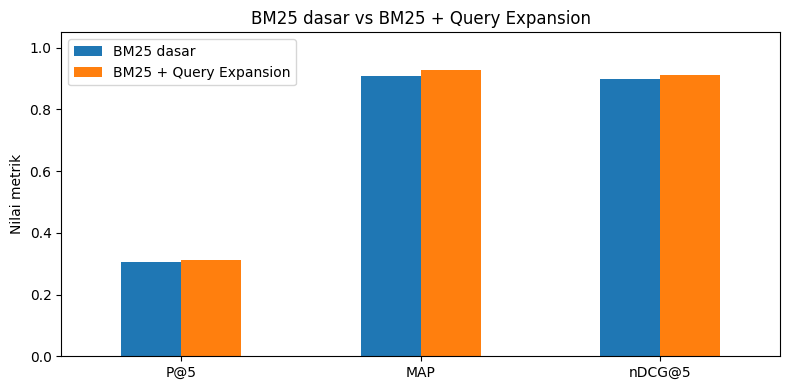

In [42]:
hasil_dasar = evaluasi_mesin(bm25_dasar)
hasil_ekspansi = evaluasi_mesin(bm25_ekspansi)
tabel_perbandingan = pd.DataFrame({
    'BM25 dasar': ringkasan(hasil_dasar),
    'BM25 + Query Expansion': ringkasan(hasil_ekspansi),
}).T
print('Perbandingan hasil rata-rata dari 25 query:')
display(tabel_perbandingan.round(4))

selisih = tabel_perbandingan.loc['BM25 + Query Expansion'] - tabel_perbandingan.loc['BM25 dasar']
print('Selisih (sistem ditingkatkan - dasar):')
print(selisih.round(4).to_string())

ax = tabel_perbandingan.T.plot(kind='bar', figsize=(8, 4), rot=0)
ax.set_title('BM25 dasar vs BM25 + Query Expansion')
ax.set_ylabel('Nilai metrik')
ax.set_ylim(0, 1.05)
plt.tight_layout()
plt.show()

### 5. Analisis kegagalan, kesimpulan, dan bahan laporan

Query dengan AP terendah pada BM25 dasar ditampilkan pada cell berikut. Saya membandingkan ranking dengan dokumen yang dianggap relevan, lalu melihat token query yang tidak ditemukan pada teks dokumen tersebut.

Ini menjadi dasar pembahasan pada laporan 6–10 halaman: pendahuluan, metode, hasil evaluasi, analisis kegagalan, dan kesimpulan. **Notebook ini memuat hasil eksperimennya, tetapi bukan pengganti laporan 6–10 halaman.**

In [43]:
qid_terburuk = hasil_dasar['AP'].idxmin()
query_terburuk = DAFTAR_QUERY[qid_terburuk]
ranking_terburuk = bm25_dasar.cari(query_terburuk, k=len(df_korpus))
print('Query dengan AP terendah:', qid_terburuk, '-', query_terburuk)
print('AP:', round(hasil_dasar.loc[qid_terburuk, 'AP'], 4))
print('Top 5 dokumen:', ranking_terburuk[:5])

ringkas_gagal = []
token_query = set(preprocess(query_terburuk))
for doc_id, grade in QRELS_012[qid_terburuk].items():
    d = bm25_dasar.korpus.loc[doc_id]
    token_doc = set(preprocess(str(d['judul']) + ' ' + str(d['isi'])))
    ringkas_gagal.append({
        'doc_id': doc_id, 'skor_relevansi': grade,
        'peringkat': ranking_terburuk.index(doc_id) + 1 if doc_id in ranking_terburuk else 'tidak muncul',
        'kata_query_cocok': ', '.join(sorted(token_query & token_doc)) or '—',
        'kata_query_tidak_cocok': ', '.join(sorted(token_query - token_doc)) or '—',
    })
display(pd.DataFrame(ringkas_gagal))

print('Kesimpulan berdasarkan data yang dijalankan:')
for metrik in ['P@5','MAP','nDCG@5']:
    delta = selisih[metrik]
    status = ('meningkat' if delta > 1e-10 else 'menurun' if delta < -1e-10 else 'tidak berubah')
    print(f'- {metrik}: {status} ({delta:+.4f})')
print('Catatan: hasil saat ini menggunakan', 'Sastrawi' if SASTRAWI_AKTIF else 'preprocessing tanpa Sastrawi')
print('Keterbatasan: korpus masih 50 dokumen lintas domain dan qrels masih perlu pemeriksaan manual.')

Query dengan AP terendah: Q06 - Keamanan siber dan serangan terhadap sistem komputer
AP: 0.5
Top 5 dokumen: ['D33', 'D10', 'D11', 'D24', 'D34']


,doc_id,skor_relevansi,peringkat,kata_query_cocok,kata_query_tidak_cocok
0,D33,2,1,"aman, serang, siber, sistem",komputer
1,D30,2,tidak muncul,—,"aman, komputer, serang, siber, sistem"
2,D10,1,2,"aman, sistem","komputer, serang, siber"


Kesimpulan berdasarkan data yang dijalankan:
- P@5: meningkat (+0.0080)
- MAP: meningkat (+0.0187)
- nDCG@5: meningkat (+0.0125)
Catatan: hasil saat ini menggunakan Sastrawi
Keterbatasan: korpus masih 50 dokumen lintas domain dan qrels masih perlu pemeriksaan manual.


**Catatan pengumpulan:** data asli tidak diubah. Untuk menjalankan ulang, buka notebook dari folder `notebooks/` dalam paket ini dan gunakan **Run All**. Jika pustaka Sastrawi belum ada, instal dan jalankan ulang sebelum mengambil angka akhir. Ketentuan 100 dokumen dari satu domain dan laporan terpisah 6–10 halaman masih perlu dipenuhi.